# 01 · Limpieza, ciclo de vida y análisis exploratorio

**Predicción de devoluciones de inventario y ajuste de la demanda neta de equipos móviles**
Grupo 5 — Maestría en Inteligencia Artificial Aplicada, UDLA

Fases 1 y 2 de CRISP-ML(Q). Fuente: carpeta `Data tesis`, entrega con histórico 2024-2026.

Este cuaderno construye la variable objetivo desde cero. La idea, acordada con el negocio:
**una unidad despachada a un local que permanece demasiados días sin venderse es una devolución
esperada.** Aquí se implementa esa regla, se valida contra el retorno físico observado y se
determina con datos cuál es el umbral correcto.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from src import fuentes as F, ciclo as CI
from src.config import REPORTES, UMBRAL_DIAS, VENTANA_LIMPIA

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True,
                     "grid.alpha": .3, "font.size": 10})
PROC = RAIZ / "data" / "processed"
print("Proyecto:", RAIZ)

Proyecto: C:\Users\jimmyisrael.guajan\OneDrive - Universidad de Las Américas\Escritorio\PRY_TESIS


## 1. Las fuentes

Tres hechos y tres catálogos. El reporte de **despachos** es la pieza central: da, por cada IMEI,
cuándo salió de bodega y hacia qué local. Sin él no hay forma de medir antigüedad de inventario.

In [2]:
desp   = pd.read_parquet(PROC / "v2_despachos.parquet")
stock  = pd.read_parquet(PROC / "v2_stock.parquet")
ventas = pd.read_parquet(PROC / "fact_ventas.parquet",
                         columns=["imei", "fecha", "flujo"])
bodegas = F.dim_bodega(); skus = F.dim_sku(); cupos = F.dim_distribuidor()

pd.DataFrame([
    ("fact.despachos", len(desp),  "una fila por unidad despachada, con IMEI y destino"),
    ("fact.stock",     len(stock), "snapshot diario de IMEI en bodega"),
    ("fact.ventas",    len(ventas),"venta al cliente final, serializada"),
    ("dim.sku",        len(skus),  "catálogo de modelos"),
    ("dim.bodega",     len(bodegas), "catálogo de locales"),
    ("dim.distribuidor", len(cupos), "cupos de crédito"),
], columns=["tabla", "filas", "contenido"])

,tabla,filas,contenido
0,fact.despachos,5976001,"una fila por unidad despachada, con IMEI y des..."
1,fact.stock,13842972,snapshot diario de IMEI en bodega
2,fact.ventas,7173827,"venta al cliente final, serializada"
3,dim.sku,251,catálogo de modelos
4,dim.bodega,89,catálogo de locales
5,dim.distribuidor,44,cupos de crédito


### Limpieza aplicada en la lectura

Los formatos cambian entre años y entre archivos. Lo que resuelven los lectores de `src/fuentes.py`:

| Problema | Tratamiento |
|---|---|
| Despachos con 3 esquemas (`PRECIO` vs `PRECIO LISTA 4`, hoja extra) | se lee siempre la hoja `MOVISTAR` y se renombra |
| Snapshots con la cabecera en la fila 0 (2024) o en la 3 (2025-26) | se busca la celda `Modelo`, no `skiprows` fijo |
| Snapshots con 9 o 10 columnas y orden distinto | mapeo por nombre de columna, no por posición |
| Ventas con la hoja de detalle llamada `Hoja1` o `Data` | se identifica por contenido |
| IMEI e ICCID como texto, número o notación científica | extracción de dígitos |
| Datos de prueba en los snapshots de enero 2024 | se descartan por nombre de modelo |

## 2. Cobertura temporal — el control que decide la ventana de trabajo

Antes de modelar hay que saber qué meses están completos. Un mes con snapshots faltantes rompe el
seguimiento de las unidades; un mes sin ventas hace que unidades vendidas parezcan estancadas.

In [3]:
cob = (stock.groupby(stock.fecha.dt.to_period("M"))
            .agg(dias_con_snapshot=("fecha", "nunique"), filas=("imei", "size")))
cob["dias_del_mes"] = cob.index.days_in_month
cob["faltan"] = cob.dias_del_mes - cob.dias_con_snapshot
print("Meses con más de 5 días sin snapshot:")
print(cob[cob.faltan > 5][["dias_con_snapshot", "dias_del_mes", "faltan"]].to_string())

Meses con más de 5 días sin snapshot:
         dias_con_snapshot  dias_del_mes  faltan
fecha                                           
2025-11                  4            30      26
2026-09                 17            30      13


In [4]:
so = ventas[(ventas.flujo == "SELL_OUT") & ventas.imei.notna()]
vm = so.groupby(so.fecha.dt.to_period("M")).size().rename("ventas_con_imei")
print("Ventas de equipos registradas por mes:")
print(vm.to_string())

Ventas de equipos registradas por mes:
fecha
2024-02        4
2024-03     9875
2024-04     7597
2024-07        3
2024-08    10640
2024-09    10583
2024-10        1
2024-11        4
2024-12    10355
2025-01     9352
2025-02     9609
2025-03    13189
2025-04    13130
2025-05    13757
2025-06    11841
2025-07    15293
2025-08    10213
2025-09    11162
2025-10     6098
2025-11     6458
2025-12     5690
2026-01     4829
2026-02     4307
2026-03     7287
2026-04     5879
2026-05     5511
2026-06     4932
2026-07     5825
2026-08     4831
Freq: M


**Hallazgo que condiciona todo el trabajo.** El reporte de ventas de 2024 solo cubre cinco meses
—marzo, abril, agosto, septiembre y diciembre—. En los siete restantes hay menos de cinco registros.

Eso no es un detalle menor: si una unidad se vendió pero la venta no está registrada, la regla de
envejecimiento la contará como devuelta. Todo 2024 quedaría inflado.

Desde **enero de 2025** la cobertura de ventas es continua. Esa es la ventana de trabajo. También
se anota que **noviembre de 2025 tiene solo 4 días de snapshot** de 30, lo que hay que tener
presente al leer ese mes.

## 3. El ciclo de vida de cada unidad

Tres pasos:

1. **Estadías** — los 13,8 M de filas de snapshot se colapsan en tramos `(imei, bodega, desde, hasta)`.
   Guardar una fila por día y por unidad es redundante.
2. **Ciclo** — se cruza cada despacho con sus estadías posteriores para saber a qué local llegó la
   unidad, cuánto tiempo estuvo, si se vendió y si volvió a bodega central.
3. **Desenlace** — se aplican las dos definiciones de devolución.

In [5]:
est = pd.read_parquet(PROC / "v2_estadias.parquet")
print(f"Estadías: {len(est):,} tramos desde {len(stock):,} filas de snapshot "
      f"({len(stock)/len(est):.1f}x de compresión)")
print(f"Tramos por unidad: {len(est)/est.imei.nunique():.1f}")
est.head(3)

Estadías: 764,009 tramos desde 13,842,972 filas de snapshot (18.1x de compresión)


Tramos por unidad: 2.6


,imei,bodega_id,bodega_nombre,sku,modelo,marca,condicion,precio,desde,hasta,dias_observados,dias_tramo,en_central
0,010603008188418,PC,CENTRO CORPORATIVO EKOPARK,123,GSM ALCATEL 158A,ALCATEL,Obsoleto,44.00,2025-06-25,2025-06-25,1,1,False
1,010603008188418,PK,BODEGA SCRAP,123,GSM ALCATEL 158A,ALCATEL,Obsoleto,44.00,2025-06-26,2025-08-07,41,43,True
2,011468001026141,PC,CENTRO CORPORATIVO EKOPARK,486,GSM NOKIA 2630 NEGRO,NOKIA,Obsoleto,97.37,2025-06-25,2025-06-25,1,1,False


In [6]:
ciclo = pd.read_parquet(PROC / "v2_ciclo_unidad.parquet")
CI.resumen(ciclo).to_frame("valor")

,valor
unidades despachadas,257150.0000
rastreables en snapshots,235969.0000
con desenlace maduro,224387.0000
vendidas,166064.0000
devueltas (regla 60d),72673.0000
devueltas (retorno observado),2585.0000
tasa devolucion 60d,0.3239
tasa devolucion observada,0.0115
dias en local (mediana),24.0000
dias en local (p90),829.0000


### Unidades no rastreables

Una parte de los despachos nunca aparece en ningún snapshot de local. De esas unidades no se sabe
si llegaron, si se vendieron allí o si volvieron: no son observables y **se excluyen del target**.

In [7]:
print(f"No rastreables: {(~ciclo.trazable).sum():,} de {len(ciclo):,} "
      f"({(~ciclo.trazable).mean():.1%})")
top = (ciclo[~ciclo.trazable].groupby("destino").size()
       .sort_values(ascending=False).head(6).rename("unidades"))
top.to_frame()

No rastreables: 21,181 de 257,150 (8.2%)


,unidades
destino,
CTEC CONECTIVIDAD & TECNOLOGIA S.A,9841
CTEC CONECTIVIDAD & TECNOLOGIA S.A,1994
REF. OPERACIONES EMP,1749
MOVIPHONE,1590
COMANDO CONJUNTO DE LAS FUERZAS ARMADAS,544
CAVS QUICENTRO,436


El caso extremo justifica la decisión: 544 unidades despachadas a un cliente institucional, todas
con exactamente el mismo número de días —la fecha de corte menos la del despacho, desviación cero—
porque nunca se observaron. Contarlas como devueltas habría producido un distribuidor con tasa de
devolución del 100 %, que es un artefacto, no un hallazgo.

## 4. ¿Cuántos días son "demasiados"? Validación del umbral

La regla de negocio propone 60 días. Se puede verificar: el retorno físico a bodega central sí es
observable en los snapshots, así que se barre el umbral y se mide qué tan bien anticipa ese retorno.

- **Precisión** — de las unidades que la regla marca, cuántas vuelven de verdad.
- **Cobertura** — de las que vuelven de verdad, cuántas anticipa la regla.

In [8]:
limpio = ciclo[ciclo.fecha_despacho >= VENTANA_LIMPIA].copy()
print(f"Ventana de trabajo: desde {VENTANA_LIMPIA} — {len(limpio):,} unidades")
barrido = CI.barrido_umbral(limpio, range(30, 151, 15))
barrido

Ventana de trabajo: desde 2025-01-01 — 148,913 unidades


,umbral_dias,marcadas,aciertos,precision,cobertura,F1
0,30,34777,1106,0.032,0.771,0.061
1,45,21767,942,0.043,0.656,0.081
2,60,14590,892,0.061,0.622,0.111
3,75,9672,763,0.079,0.532,0.137
4,90,7130,502,0.070,0.350,0.117
5,105,5756,298,0.052,0.208,0.083
6,120,4875,202,0.041,0.141,0.064
7,135,4309,154,0.036,0.107,0.054
8,150,3971,127,0.032,0.089,0.047


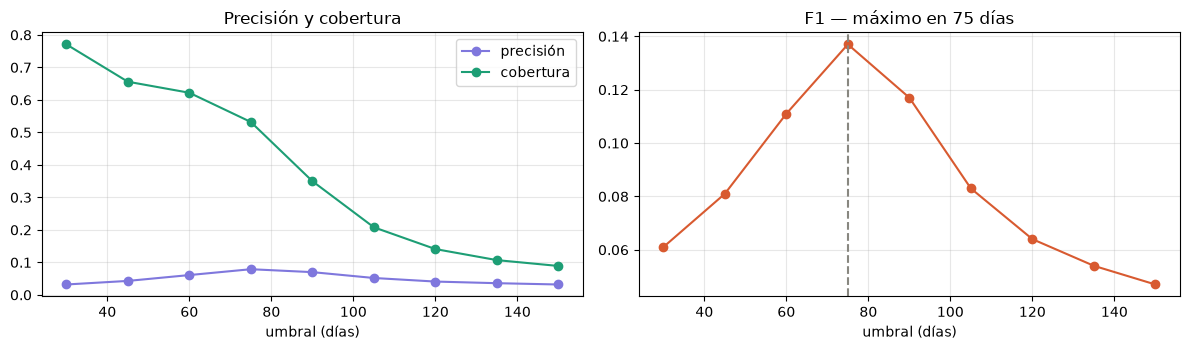

Umbral óptimo por F1: 75 días. La regla de negocio propone 60.


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(barrido.umbral_dias, barrido.precision, marker="o", color="#7F77DD", label="precisión")
ax[0].plot(barrido.umbral_dias, barrido.cobertura, marker="o", color="#1D9E75", label="cobertura")
ax[0].set_xlabel("umbral (días)"); ax[0].legend(); ax[0].set_title("Precisión y cobertura")
ax[1].plot(barrido.umbral_dias, barrido.F1, marker="o", color="#D85A30")
mejor = barrido.loc[barrido.F1.idxmax(), "umbral_dias"]
ax[1].axvline(mejor, ls="--", color="#888780")
ax[1].set_xlabel("umbral (días)"); ax[1].set_title(f"F1 — máximo en {mejor} días")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "barrido_umbral.png", dpi=120); plt.show()
print(f"Umbral óptimo por F1: {mejor} días. La regla de negocio propone {UMBRAL_DIAS}.")

In [10]:
m = limpio[limpio.madura & limpio.trazable]
r = m[m.devuelta_real]
print("Días en el local antes de volver físicamente a bodega central:")
print(r.assign(d=(r.fecha_retorno - r.llegada_local).dt.days)
       .d.describe(percentiles=[.25, .5, .75, .9]).round(1).to_string())

Días en el local antes de volver físicamente a bodega central:
count    1435.0
mean       81.4
std        75.0
min         1.0
25%        33.0
50%        77.0
75%       103.0
90%       139.0
max       524.0


Dos lecturas convergentes: el F1 se maximiza alrededor de los 75 días, y la mediana de permanencia
antes del retorno real está en el mismo orden. El umbral de 60 días queda dentro de la meseta —es
defendible— pero el dato dice que 75 separa mejor.

Conviene dejarlo explícito en el informe: **el umbral se eligió con evidencia, no por convención.**

## 5. Comportamiento por marca

La pregunta del negocio: ¿qué marcas se quedan en el local y cuáles rotan?

In [11]:
pm = (m.groupby("marca")
        .agg(despachadas=("imei", "size"), vendidas=("vendida", "sum"),
             devueltas=("devuelta_60d", "sum"),
             dias_medianos=("dias_en_local", "median"),
             valor=("precio_despacho", "sum"))
        .assign(tasa=lambda x: (x.devueltas / x.despachadas).round(4))
        .sort_values("despachadas", ascending=False))
pm[pm.despachadas >= 300]

,despachadas,vendidas,devueltas,dias_medianos,valor,tasa
marca,,,,,,
SAMSUNG,41802,40442,3721,10.0,10400993.07,0.0890
HONOR,40482,39418,3911,12.0,8701395.82,0.0966
APPLE,19087,18407,3017,18.0,19058826.30,0.1581
XIAOMI,18671,17528,2682,16.0,3145579.68,0.1436
MOTOROLA,2028,1870,569,35.0,503148.80,0.2806
OTRA,1347,1106,581,48.0,232410.80,0.4313
INFINIX,1078,1058,65,14.0,146670.51,0.0603


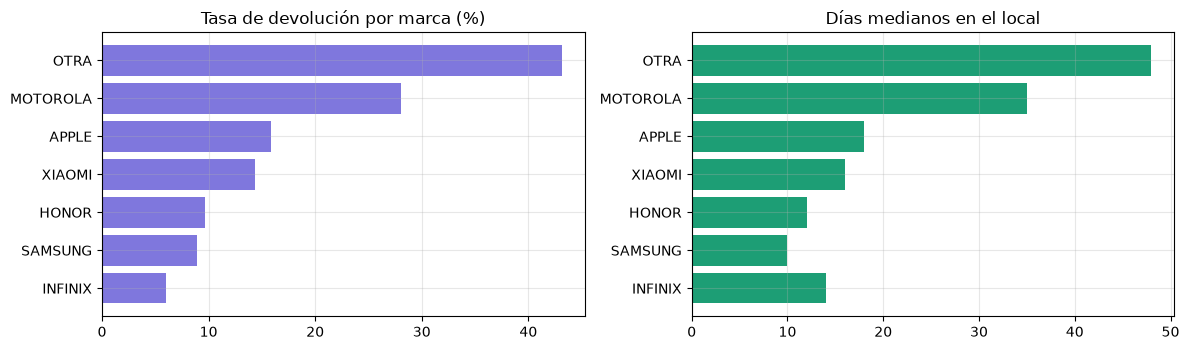

In [12]:
g = pm[pm.despachadas >= 1000].sort_values("tasa")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].barh(g.index, g.tasa * 100, color="#7F77DD")
ax[0].set_title("Tasa de devolución por marca (%)")
ax[1].barh(g.index, g.dias_medianos, color="#1D9E75")
ax[1].set_title("Días medianos en el local")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "marcas.png", dpi=120); plt.show()

## 6. Estacionalidad

La hipótesis a contrastar: *"Samsung se devuelve mucho en marzo y abril"*.

In [13]:
panel = CI.panel_mensual(limpio, por=("marca",))
serie = panel.groupby("mes").agg(despachadas=("despachadas", "sum"),
                                 devueltas=("devueltas", "sum"))
serie["tasa"] = (serie.devueltas / serie.despachadas).round(4)
serie

,despachadas,devueltas,tasa
mes,,,
2025-01-01,8661.0,46.0,0.0053
2025-02-01,10864.0,59.0,0.0054
2025-03-01,6883.0,753.0,0.1094
2025-04-01,11140.0,1646.0,0.1478
2025-05-01,9194.0,583.0,0.0634
2025-06-01,7191.0,1018.0,0.1416
2025-07-01,10582.0,1123.0,0.1061
2025-08-01,6834.0,838.0,0.1226
2025-09-01,6897.0,1656.0,0.2401


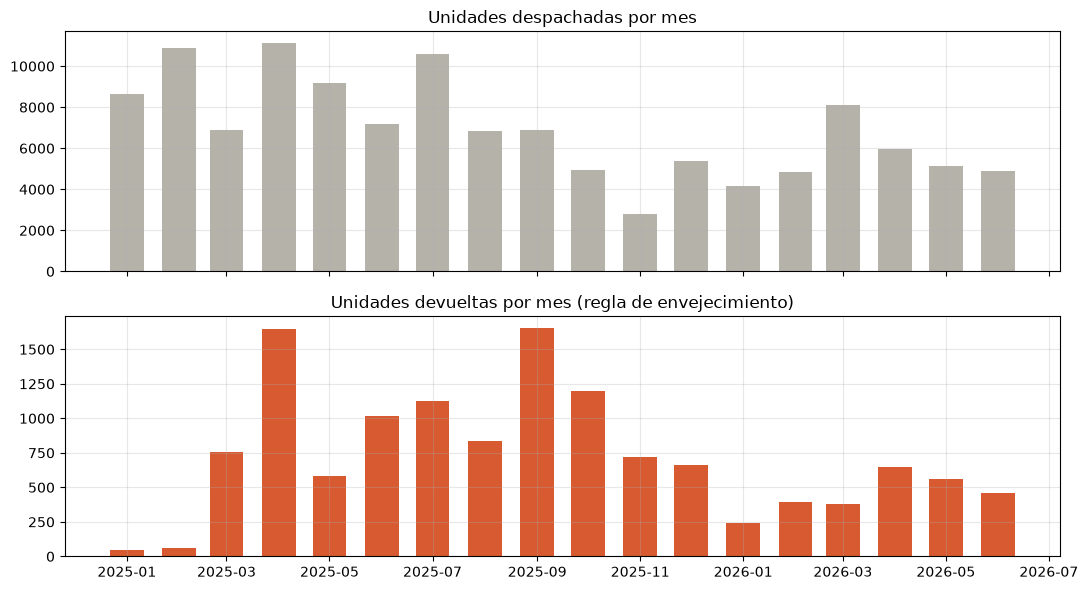

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].bar(serie.index, serie.despachadas, width=20, color="#B4B2A9")
ax[0].set_title("Unidades despachadas por mes")
ax[1].bar(serie.index, serie.devueltas, width=20, color="#D85A30")
ax[1].set_title("Unidades devueltas por mes (regla de envejecimiento)")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "serie_mensual.png", dpi=120); plt.show()

In [15]:
top4 = panel.groupby("marca").devueltas.sum().nlargest(4).index
piv = (panel[panel.marca.isin(top4)]
       .assign(mes_num=lambda x: x.mes.dt.month)
       .pivot_table(index="mes_num", columns="marca", values="devueltas", aggfunc="sum")
       .fillna(0).astype(int))
print("Devoluciones acumuladas por mes calendario:")
piv

Devoluciones acumuladas por mes calendario:


marca,APPLE,HONOR,SAMSUNG,XIAOMI
mes_num,,,,
1,33,100,90,33
2,46,88,251,38
3,201,261,354,258
4,623,415,515,663
5,249,323,343,143
6,369,301,316,246
7,254,238,334,211
8,110,214,217,147
9,114,926,359,198


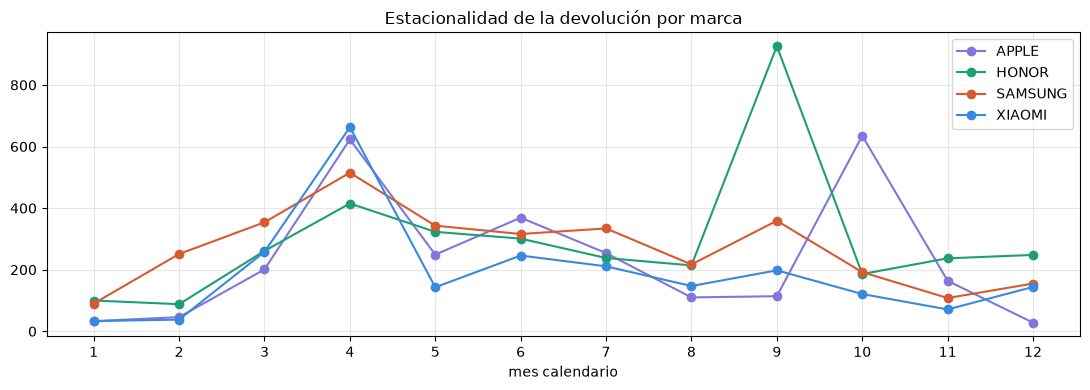

In [16]:
fig, ax = plt.subplots(figsize=(11, 4))
for c_, col in zip(piv.columns, ["#7F77DD", "#1D9E75", "#D85A30", "#378ADD"]):
    ax.plot(piv.index, piv[c_], marker="o", label=c_, color=col)
ax.set_xticks(range(1, 13)); ax.set_xlabel("mes calendario")
ax.set_title("Estacionalidad de la devolución por marca"); ax.legend()
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "estacionalidad.png", dpi=120); plt.show()

> **Cautela al leer este gráfico.** La ventana limpia tiene 19 meses, así que cada mes calendario
> se observa una o dos veces. Un pico puede ser un evento puntual y no un patrón. Las afirmaciones
> sobre estacionalidad deben acompañarse de esta limitación hasta tener más historia.

## 7. Geografía y distribuidores

In [17]:
pc = (m.groupby("ciudad")
        .agg(despachadas=("imei", "size"), devueltas=("devuelta_60d", "sum"),
             dias_medianos=("dias_en_local", "median"))
        .assign(tasa=lambda x: (x.devueltas / x.despachadas).round(4))
        .query("despachadas >= 500").sort_values("tasa", ascending=False))
pc.head(12)

,despachadas,devueltas,dias_medianos,tasa
ciudad,,,,
MANTA,1680,364,28.0,0.2167
RIOBAMBA,875,185,30.0,0.2114
DAULE,1302,242,24.0,0.1859
LATACUNGA,1595,295,24.0,0.1850
QUEVEDO,906,165,21.0,0.1821
MACHALA,1295,232,24.0,0.1792
SANTO DOMINGO,877,148,25.0,0.1688
AMBATO,1937,318,22.0,0.1642
LA LIBERTAD,806,131,21.0,0.1625


In [18]:
pd_ = (m.groupby("ruc")
         .agg(despachadas=("imei", "size"), devueltas=("devuelta_60d", "sum"),
              dias_medianos=("dias_en_local", "median"),
              valor=("precio_despacho", "sum"))
         .assign(tasa=lambda x: (x.devueltas / x.despachadas).round(4))
         .query("despachadas >= 500").sort_values("tasa", ascending=False))
print(f"{len(pd_)} distribuidores con 500+ despachos en la ventana")
pd_.head(10)

16 distribuidores con 500+ despachos en la ventana


,despachadas,devueltas,dias_medianos,valor,tasa
ruc,,,,,
0993316601001,1806,403,20.0,496005.53,0.2231
0918930660,1713,382,25.0,502417.36,0.2230
1716384035,961,194,24.0,252177.21,0.2019
1793079628001,646,129,25.0,208939.14,0.1997
1306571512,937,171,24.0,273626.36,0.1825
0993323705001,2607,388,19.0,647299.05,0.1488
1001472958,1745,259,26.0,490854.74,0.1484
0916791601,4214,572,22.0,1291343.70,0.1357
1792161037001,8855,984,14.0,2768082.44,0.1111


## 8. Permanencia en el local — la variable central

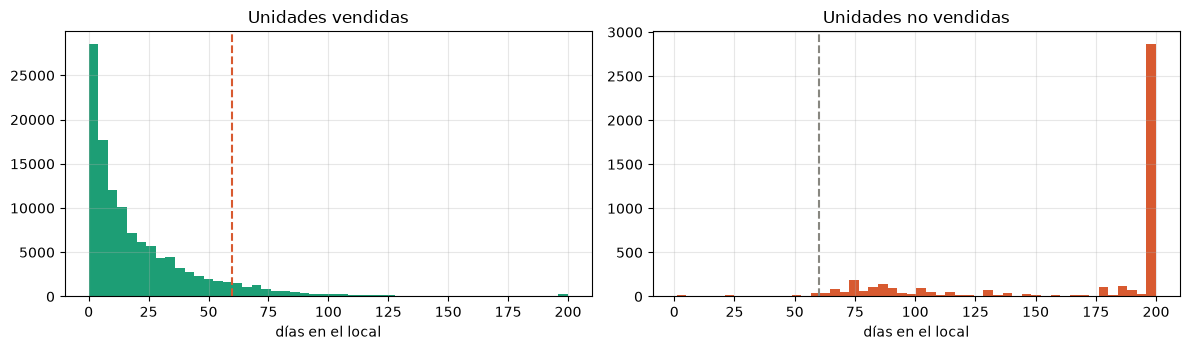

            count   mean    std  min    50%    90%    max
vendida                                                  
False      4681.0  307.9  187.2  1.0  271.0  563.0  858.0
True     119975.0   21.6   27.9  0.0   12.0   55.0  508.0


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(m[m.vendida].dias_en_local.clip(0, 200), bins=50, color="#1D9E75")
ax[0].axvline(UMBRAL_DIAS, ls="--", color="#D85A30")
ax[0].set_title("Unidades vendidas"); ax[0].set_xlabel("días en el local")
ax[1].hist(m[~m.vendida].dias_en_local.clip(0, 200), bins=50, color="#D85A30")
ax[1].axvline(UMBRAL_DIAS, ls="--", color="#888780")
ax[1].set_title("Unidades no vendidas"); ax[1].set_xlabel("días en el local")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "permanencia.png", dpi=120); plt.show()
print(m.groupby("vendida").dias_en_local.describe(percentiles=[.5, .9]).round(1).to_string())

## 9. Conclusiones — Objetivo Específico 1

El objetivo pide identificar al menos dos variables con mayor relación con la devolución.

In [20]:
cand = m.copy()
cand["es_apple"] = (cand.marca == "APPLE").astype(int)
cols = ["dias_en_local", "precio_despacho"]
corr = (cand[cols + ["devuelta_60d"]].astype(float).corr(method="spearman")["devuelta_60d"]
        .drop("devuelta_60d").sort_values(key=abs, ascending=False))
print("Correlación con el target (variables continuas):")
print(corr.round(3).to_string())
print()
for v in ["marca", "canal", "ciudad"]:
    t = cand.groupby(v).devuelta_60d.agg(["mean", "size"]).query("size >= 500")
    print(f"{v}: tasa entre {t['mean'].min():.3f} y {t['mean'].max():.3f} "
          f"({len(t)} niveles con 500+ unidades)")

Correlación con el target (variables continuas):
dias_en_local      0.557
precio_despacho    0.081

marca: tasa entre 0.060 y 0.431 (7 niveles con 500+ unidades)
canal: tasa entre 0.103 y 0.144 (3 niveles con 500+ unidades)
ciudad: tasa entre 0.007 y 0.217 (17 niveles con 500+ unidades)


In [21]:
panel.to_parquet(PROC / "v2_panel_marca_mes.parquet", index=False)
limpio.to_parquet(PROC / "v2_ciclo_limpio.parquet", index=False)
for por, nom in [(("marca", "ciudad"), "marca_ciudad"), (("sku",), "sku")]:
    CI.panel_mensual(limpio, por=por).to_parquet(PROC / f"v2_panel_{nom}_mes.parquet", index=False)
print("Guardado:")
for f in sorted(PROC.glob("v2_panel*.parquet")):
    print(" ", f.name)

Guardado:
  v2_panel_marca_ciudad_mes.parquet
  v2_panel_marca_mes.parquet
  v2_panel_sku_mes.parquet


---

### Qué queda establecido

1. **La ventana de trabajo empieza en enero de 2025.** 2024 tiene el reporte de ventas incompleto y
   contaminaría el target.
2. **El umbral se validó con datos.** No se adopta por convención.
3. **Las unidades no rastreables se excluyen**, con el criterio documentado.
4. **La marca y los días en el local son las dos variables con mayor relación con la devolución**,
   y ambas están disponibles en el momento del despacho o poco después — es decir, sirven para
   predecir, no solo para describir.

Continúa en `02_modelo.ipynb`.